In [1]:
import os

os.environ['PYEPICS_LIBCA'] = '/usr/local/share/pynq-venv/lib/python3.10/site-packages/epicscorelibs/lib/libca.so'
os.environ["EPICS_CA_AUTO_ADDR_LIST"] = "NO"  
os.environ["EPICS_CA_ADDR_LIST"] = "192.168.2.99"

import interleaving_adc_calibration as cal
import plot_spur_spectrum as pltspur

%cd /home/xilinx/jupyter_notebooks/pynq_llrf

import numpy as np
import matplotlib.pyplot as plt
import epics
from mimo_mts.overlay import MimoMtsOverlay

FS = 4000
DECIMATION = 16
ADC_CH = 4
NCO_OFFSET = 2973
CAL_FILE = "/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json"

/home/xilinx/jupyter_notebooks/pynq_llrf


In [2]:
if 'ol' not in globals():
    ol = MimoMtsOverlay(config='ALS_LLRF_ZCU208')
    rfdc = ol.rfdc

Device-tree overlay is already applied: /home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/overlays/lmxadc.dtbo
flash
lmk
{'lmk': {'spi_device': PosixPath('/dev/spidev1.1'), 'compatible': 'ti,lmk04828', 'num_bytes': 3}}
lmxdac
{'lmk': {'spi_device': PosixPath('/dev/spidev1.1'), 'compatible': 'ti,lmk04828', 'num_bytes': 3}, 'lmxdac': {'spi_device': PosixPath('/dev/spidev1.2'), 'compatible': 'ti,lmx2594', 'num_bytes': 3}}
lmxadc
{'lmk': {'spi_device': PosixPath('/dev/spidev1.1'), 'compatible': 'ti,lmk04828', 'num_bytes': 3}, 'lmxdac': {'spi_device': PosixPath('/dev/spidev1.2'), 'compatible': 'ti,lmx2594', 'num_bytes': 3}, 'lmxadc': {'spi_device': PosixPath('/dev/spidev1.0'), 'compatible': 'ti,lmx2594', 'num_bytes': 3}}


Set DAC mixer: freq=-3000 MHz, nyquist=2, phase=0 degrees
Set ADC mixers configuration (Per-Channel Multi-Frequency Enabled; EPICS mapping normalized).


Set the Signal Generator to 3 GHz, CW, - 5dBm.
Adjust the power level until the fundamental recevied power level is -9 dBFS (~-5 dBm) using the cell below.

Reading live waveforms from EPICS...

           DETECTED SPURS / PEAKS (> -95 dBFS)            
 #    | Frequency Offset (MHz) | Power (dBFS)   | Type
----------------------------------------------------------
 1    |                0.004    |       -13.93    | Carrier
 2    |               -0.378    |       -87.06    | Spur / Image
 3    |                0.385    |       -87.55    | Spur / Image
 4    |               -0.233    |       -87.98    | Spur / Image
 5    |                0.240    |       -89.06    | Spur / Image
 6    |               62.506    |       -89.45    | Spur / Image
 7    |              -62.498    |       -89.81    | Spur / Image
 8    |                0.767    |       -94.37    | Spur / Image
 9    |               -0.759    |       -94.40    | Spur / Image



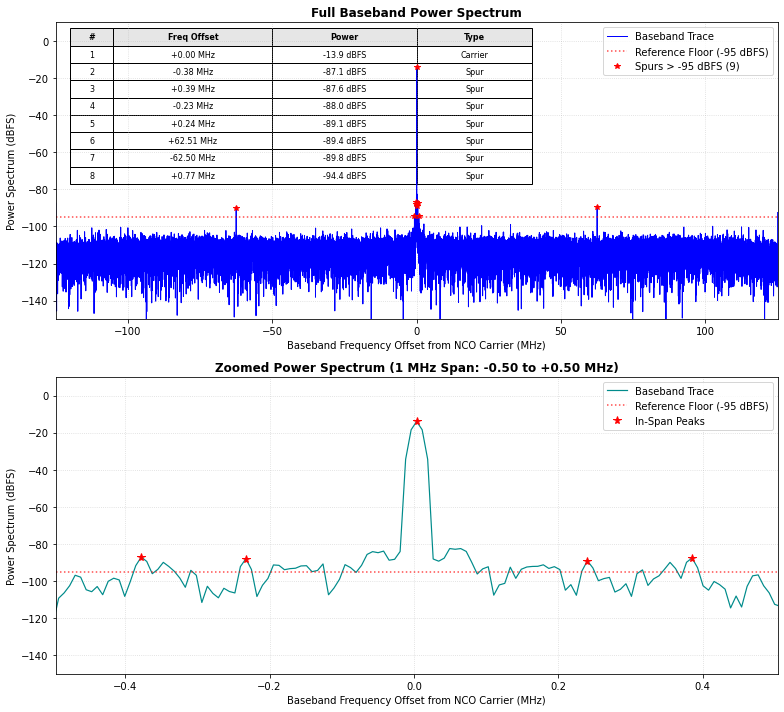

In [13]:
I_WAVEFORM_PV = "ALS_LLRF_ZCU208:ADC7:IWF"
Q_WAVEFORM_PV = "ALS_LLRF_ZCU208:ADC7:QWF"
FS_EFFECTIVE_MHZ = FS/DECIMATION  # Decimated sampling rate

pltspur.plot_spur_spectrum(I_WAVEFORM_PV,Q_WAVEFORM_PV,FS_EFFECTIVE_MHZ)

###### Move Signal Generator off frequency to 2.973 GHz

In [18]:
NCO_PV = "ALS_LLRF_ZCU208:rfdc_mixer:adc_mixer_nco_freq_mhz"
epics.caput(NCO_PV, NCO_OFFSET)

1

In [16]:
#cal.read_cal_registers(rfdc, adc_ch=ADC_CH)
cal.read_adc_cal(rfdc, adc_ch='all')


--- ADC 0 Interleaving Readback (Tile 0, Block 0) ---
Status: 🔴 FROZEN
--------------------------------------------------------------------------------
  ├── OCB1 (Offset Background)  : [4292345792, 4294770602, 524313, 1966064, 0, 0, 0, 0]
  ├── OCB2 (Offset Foreground)  : [10289289, 9961600, 9830540, 8978566, 0, 0, 0, 0]
  ├── GCB  (Gain Cal Block)      : [131072, 458764, 135112, 268308442, 0, 0, 0, 0]
  ├── TSCB (Time Skew Cal Block) : [33489407, 33489407, 33489407, 33489407, 33489407, 197119, 33489407, 33489407]
--------------------------------------------------------------------------------

--- ADC 1 Interleaving Readback (Tile 0, Block 1) ---
Status: 🔴 FROZEN
--------------------------------------------------------------------------------
  ├── OCB1 (Offset Background)  : [4292739037, 4292018111, 4294639650, 1507338, 0, 0, 0, 0]
  ├── OCB2 (Offset Foreground)  : [4784156, 3538970, 3801137, 3866662, 0, 0, 0, 0]
  ├── GCB  (Gain Cal Block)      : [267649024, 267915254, 266862592, 

In [5]:
cal.freeze_adc_cal(rfdc, adc_ch='all', freeze=True)

🔴 [FROZEN] ADC 0 (Tile 0, Block 0) interleaving calibration updated.
🔴 [FROZEN] ADC 1 (Tile 0, Block 1) interleaving calibration updated.
🔴 [FROZEN] ADC 2 (Tile 1, Block 0) interleaving calibration updated.
🔴 [FROZEN] ADC 3 (Tile 1, Block 1) interleaving calibration updated.
🔴 [FROZEN] ADC 4 (Tile 2, Block 0) interleaving calibration updated.
🔴 [FROZEN] ADC 5 (Tile 2, Block 1) interleaving calibration updated.
🔴 [FROZEN] ADC 6 (Tile 3, Block 0) interleaving calibration updated.
🔴 [FROZEN] ADC 7 (Tile 3, Block 1) interleaving calibration updated.


In [8]:
cal.save_adc_cal(rfdc=rfdc, cal_file=CAL_FILE, adc_ch='all')

[✔] Captured ADC 0 coefficients (Tile 0, Block 0) -> Updated 'ADC0'
[✔] Captured ADC 1 coefficients (Tile 0, Block 1) -> Updated 'ADC1'
[✔] Captured ADC 2 coefficients (Tile 1, Block 0) -> Updated 'ADC2'
[✔] Captured ADC 3 coefficients (Tile 1, Block 1) -> Updated 'ADC3'
[✔] Captured ADC 4 coefficients (Tile 2, Block 0) -> Updated 'ADC4'
[✔] Captured ADC 5 coefficients (Tile 2, Block 1) -> Updated 'ADC5'
[✔] Captured ADC 6 coefficients (Tile 3, Block 0) -> Updated 'ADC6'
[✔] Captured ADC 7 coefficients (Tile 3, Block 1) -> Updated 'ADC7'
[✔] Saved calibration data to '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'


In [13]:
cal.zero_adc_cal(rfdc=rfdc, adc_ch='all')


 🔴 FORCING SUB-ADC CALIBRATION COEFFICIENTS TO ZERO

📍 ADC 0 (Tile 0, Block 0):
    ├── OCB1 (Offset Background)  : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── OCB2 (Offset Foreground)  : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── GCB  (Gain Cal Block)      : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── TSCB (Time Skew Cal Block) : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]

📍 ADC 1 (Tile 0, Block 1):
    ├── OCB1 (Offset Background)  : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── OCB2 (Offset Foreground)  : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── GCB  (Gain Cal Block)      : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── TSCB (Time Skew Cal Block) : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]

📍 ADC 2 (Tile 1, Block 0):
    ├── OCB1 (Offset Background)  : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── OCB2 (Offset Foreground)  : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── GCB  (Gain Cal Block)      : Overwritten to [0, 0, 0, 0, 0, 0, 0, 0]
    ├── TSCB (Time Ske

In [15]:
cal.restore_adc_cal(rfdc=rfdc, cal_file=CAL_FILE, adc_ch='all')

[✔] Restored ADC 0 coefficients (Tile 0, Block 0) <- Loaded 'ADC0' from '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] Restored ADC 1 coefficients (Tile 0, Block 1) <- Loaded 'ADC1' from '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] Restored ADC 2 coefficients (Tile 1, Block 0) <- Loaded 'ADC2' from '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] Restored ADC 3 coefficients (Tile 1, Block 1) <- Loaded 'ADC3' from '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] Restored ADC 4 coefficients (Tile 2, Block 0) <- Loaded 'ADC4' from '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] Restored ADC 5 coefficients (Tile 2, Block 1) <- Loaded 'ADC5' from '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] Restored ADC 6 coefficients (Tile 3, Block 0) <-

In [17]:
cal.verify_adc_cal(rfdc=rfdc, cal_file=CAL_FILE, adc_ch="all")

[✔] ADC 0 (Tile 0, Block 0) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 1 (Tile 0, Block 1) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 2 (Tile 1, Block 0) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 3 (Tile 1, Block 1) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 4 (Tile 2, Block 0) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 5 (Tile 2, Block 1) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 6 (Tile 3, Block 0) hardware registers match '/home/xilinx/jupyter_notebooks/pynq_llrf/tests/Interleaving_calibration/rf_cal.json'
[✔] ADC 7 (Tile 3, Block 1)

True